# Análisis exploratorio de datos (EDA)

## Objetivo
Explorar las transacciones de una tienda online para conocer la estructura del dataset, detectar problemas de calidad y documentar cuestiones que deberán resolverse durante la limpieza.

## Fuente de datos
- **Dataset:** Online Retail
- **Fuente:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail)
- **Autor:** Daqing Chen
- **Periodo:** del 1 de diciembre de 2010 al 9 de diciembre de 2011
- **Licencia:** Creative Commons Attribution 4.0 (CC BY 4.0)
- **Archivo:** `Online Retail.xlsx`

## 1. Descarga y Lectura del dataset

In [1]:
import pandas as pd
from pathlib import Path
import urllib.request

DATA_URL = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

DATA_DIR = Path("../data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = DATA_DIR / "Online_Retail.xlsx"
ZIP_PATH = DATA_DIR / "Online_Retail.zip"

# Descargar el dataset si todavía no existe
if not DATA_PATH.exists():
    print("Descargando dataset...")

    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

    import zipfile

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extract("Online Retail.xlsx", DATA_DIR)

    (DATA_DIR / "Online Retail.xlsx").rename(DATA_PATH)

    ZIP_PATH.unlink()

    print("Dataset descargado y guardado correctamente.")

else:
    print("El dataset ya existe. Se utilizará el archivo local.")

df = pd.read_excel(DATA_PATH)

df_clean = df.copy()

print("Dimensiones del dataset:", df_clean.shape)
display(df_clean.head())

Descargando dataset...
Dataset descargado y guardado correctamente.
Dimensiones del dataset: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Inspección del dataset

- Dimensiones
- Nombres de las columnas 
- Tipos de datos.
- Identificar posibles problemas de calidad

In [2]:
print(f"Dimensiones: {df.shape}\n")
print("Nombres de las columnas:")
print(df.columns.tolist())
print(f"\nTipos de datos:\n{df.dtypes}")

Dimensiones: (541909, 8)

Nombres de las columnas:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Tipos de datos:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object


## 3. Calidad inicial de los datos

- Filas duplicadas
- Valores ausentes

In [3]:
contar_duplicados = df.duplicated().sum()

porcentaje_duplicados = (contar_duplicados / len(df)) * 100

print(f"Filas duplicadas: {contar_duplicados}")
print(f"Porcentaje de duplicados: {porcentaje_duplicados:.2f}%")


Filas duplicadas: 5268
Porcentaje de duplicados: 0.97%


In [4]:
valores_ausentes = df.isna().sum()

resumen_valores_ausentes = pd.DataFrame({
    "Valores ausentes": valores_ausentes,
})

resumen_valores_ausentes = resumen_valores_ausentes.sort_values(
    by="Valores ausentes",
    ascending=False
)

display(resumen_valores_ausentes.round(2))


,Valores ausentes
CustomerID,135080
Description,1454
StockCode,0
InvoiceNo,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0


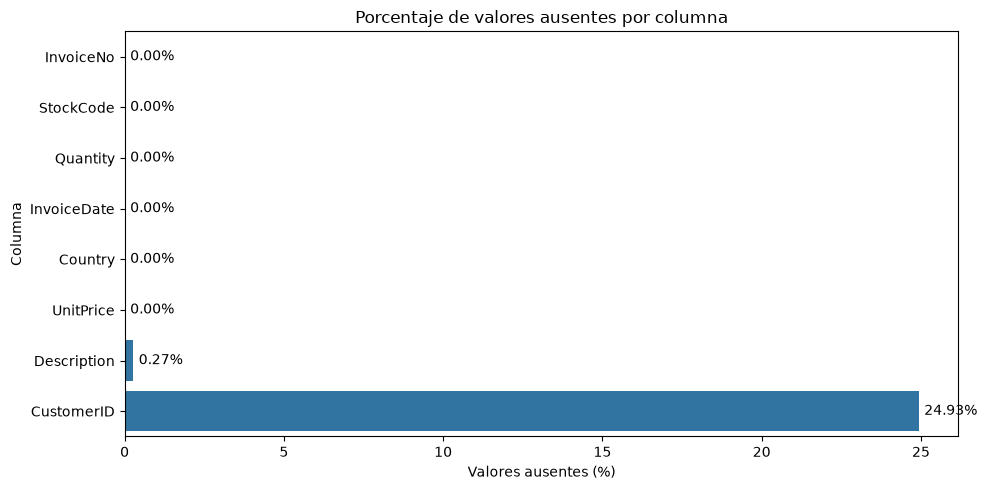

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

porcentaje_valores_ausentes = df.isna().mean().mul(100)
porcentaje_valores_ausentes = porcentaje_valores_ausentes.sort_values(ascending=True)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=porcentaje_valores_ausentes.values,
    y=porcentaje_valores_ausentes.index
)

ax.set_title("Porcentaje de valores ausentes por columna")
ax.set_xlabel("Valores ausentes (%)")
ax.set_ylabel("Columna")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=4)

plt.tight_layout()
plt.show()

## 4. Investigación de filas duplicadas

Una fila duplicada es una fila cuyos valores coinciden en todas las columnas.

Vamos a inspeccionar ejemplos de filas completamente duplicadas para comprender qué información contienen.

In [6]:
filas_duplicadas = df[df.duplicated(keep=False)]

print(f"Filas que pertenecen a grupos duplicados: {len(filas_duplicadas)}")

display(
    filas_duplicadas
    .sort_values(by=["InvoiceNo", "StockCode"])
    .head(10)
)


Filas que pertenecen a grupos duplicados: 10147


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


## 5. Análisis inicial de las transacciones

El objetivo es identificar registros que puedan corresponder a cancelaciones, devoluciones o valores que requieran revisión adicional.

No asumiremos que todos los valores negativos, ceros o valores altos son errores. Primero observaremos su frecuencia y contexto.

### 5.1 Cantidades y precios

In [7]:
display(df[["Quantity", "UnitPrice"]].describe().T)


print("\nDistribución de las cantidades:")

resumen_cantidades = pd.Series({
    "Cantidad negativa": (df["Quantity"] < 0).sum(),
    "Cantidad igual a cero": (df["Quantity"] == 0).sum(),
    "Cantidad positiva": (df["Quantity"] > 0).sum()
})

display(resumen_cantidades.to_frame(name="Número de filas"))


print("\nDistribución de los precios unitarios:")

resumen_precio = pd.Series({
    "Precio negativo": (df["UnitPrice"] < 0).sum(),
    "Precio igual a cero": (df["UnitPrice"] == 0).sum(),
    "Precio positivo": (df["UnitPrice"] > 0).sum()
})

display(resumen_precio.to_frame(name="Número de filas"))


,count,mean,std,min,25%,50%,75%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,1.00,3.00,10.00,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0



Distribución de las cantidades:


,Número de filas
Cantidad negativa,10624
Cantidad igual a cero,0
Cantidad positiva,531285



Distribución de los precios unitarios:


,Número de filas
Precio negativo,2
Precio igual a cero,2515
Precio positivo,539392


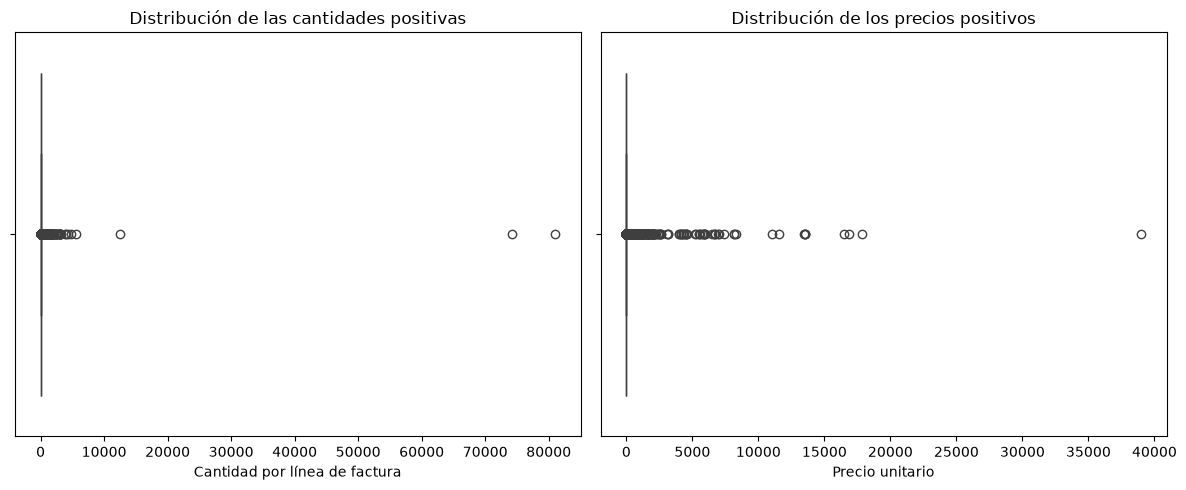

In [8]:
cantidades_positivas = df.loc[df["Quantity"] > 0, "Quantity"]
precios_positivos = df.loc[df["UnitPrice"] > 0, "UnitPrice"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Diagrama de caja de las cantidades.
sns.boxplot(
    x=cantidades_positivas,
    ax=axes[0]
)
axes[0].set_title("Distribución de las cantidades positivas")
axes[0].set_xlabel("Cantidad por línea de factura")

# Diagrama de caja de los precios unitarios.
sns.boxplot(
    x=precios_positivos,
    ax=axes[1]
)
axes[1].set_title("Distribución de los precios positivos")
axes[1].set_xlabel("Precio unitario")

plt.tight_layout()
plt.show()

### 5.2 Facturas canceladas

Según la documentación de UCI, los números de factura que comienzan por `C` indican cancelaciones. Contaremos tanto las filas asociadas a esos identificadores como el número de facturas distintas, ya que una factura puede contener varias líneas de producto.

In [9]:

numeros_factura = df["InvoiceNo"].astype("string").str.strip()

canceladas = numeros_factura.str.startswith(
    "C",
    na=False
)

print(f"Filas asociadas a facturas canceladas: {canceladas.sum()}")

print(
    "Número de facturas canceladas distintas:",
    numeros_factura[canceladas].nunique()
)

print(
    "Filas con cantidad negativa:",
    (df["Quantity"] < 0).sum()
)

display(
    df.loc[
        canceladas,
        ["InvoiceNo", "StockCode", "Quantity",
         "InvoiceDate", "UnitPrice", "CustomerID"]
    ].head(10)
)


Filas asociadas a facturas canceladas: 9288
Número de facturas canceladas distintas: 3836
Filas con cantidad negativa: 10624


,InvoiceNo,StockCode,Quantity,InvoiceDate,UnitPrice,CustomerID
141,C536379,D,-1,2010-12-01 09:41:00,27.50,14527.0
154,C536383,35004C,-1,2010-12-01 09:49:00,4.65,15311.0
235,C536391,22556,-12,2010-12-01 10:24:00,1.65,17548.0
236,C536391,21984,-24,2010-12-01 10:24:00,0.29,17548.0
237,C536391,21983,-24,2010-12-01 10:24:00,0.29,17548.0
238,C536391,21980,-24,2010-12-01 10:24:00,0.29,17548.0
239,C536391,21484,-12,2010-12-01 10:24:00,3.45,17548.0
240,C536391,22557,-12,2010-12-01 10:24:00,1.65,17548.0
241,C536391,22553,-24,2010-12-01 10:24:00,1.65,17548.0
939,C536506,22960,-6,2010-12-01 12:38:00,4.25,17897.0


### 5.3 Precios iguales a cero y negativos

Se han detectado precios unitarios iguales a cero y dos registros con precio negativo. Antes de definir su tratamiento en la fase de limpieza, se inspeccionarán los registros negativos y se resumirán los casos con precio cero más frecuentes.

In [10]:
columnas = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID"
]

filas_precio_negativo = df.loc[
    df["UnitPrice"] < 0, columnas
].sort_values("UnitPrice")

print(f"Registros con precio unitario negativo: {len(filas_precio_negativo)}")
display(filas_precio_negativo)

resumen_precio_cero = (
    df.loc[df["UnitPrice"] == 0]
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Numero_registros=("InvoiceNo", "size"),
        Cantidad_total=("Quantity", "sum")
    )
    .sort_values("Numero_registros", ascending=False)
    .head(10)
)

print("\n10 combinaciones más frecuentes con precio unitario cero:")
display(resumen_precio_cero)

Registros con precio unitario negativo: 2


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN



10 combinaciones más frecuentes con precio unitario cero:


,,Numero_registros,Cantidad_total
StockCode,Description,,
23084,NaN,10,332
35965,NaN,10,38
22084,NaN,9,-129
22676,FRENCH BLUE METAL DOOR SIGN 1,9,26
22683,FRENCH BLUE METAL DOOR SIGN 8,8,19
22679,FRENCH BLUE METAL DOOR SIGN 4,7,21
22686,FRENCH BLUE METAL DOOR SIGN No,7,26
21116,OWL DOORSTOP,7,12
22666,RECIPE BOX PANTRY YELLOW DESIGN,7,21


## 6. Investigación de valores extremos

In [11]:
print("Registros con cantidades más extremas:")

cantidad_extrema = df.loc[
    df["Quantity"].abs().nlargest(10).index
].sort_values(
    by="Quantity",
    key=lambda values: values.abs(),
    ascending=False
)

display(
    cantidad_extrema[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "InvoiceDate", "UnitPrice", "Country"]
    ]
)

print("\nRegistros con precios unitarios más extremos:")

precio_extremo = df.loc[
    df["UnitPrice"].abs().nlargest(10).index
].sort_values(
    by="UnitPrice",
    key=lambda values: values.abs(),
    ascending=False
)

display(
    precio_extremo[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "InvoiceDate", "UnitPrice", "Country"]
    ]
)

Registros con cantidades más extremas:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,United Kingdom
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,United Kingdom
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,United Kingdom
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,United Kingdom
225529,556690,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,United Kingdom
225530,556691,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,United Kingdom
4287,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,2010-12-02 14:23:00,0.03,United Kingdom
225528,556687,23003,Printing smudges/thrown away,-9058,2011-06-14 10:36:00,0.00,United Kingdom
74614,542504,37413,NaN,5568,2011-01-28 12:03:00,0.00,United Kingdom



Registros con precios unitarios más extremos:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,Country
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,United Kingdom
524602,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,United Kingdom
43702,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,16888.02,United Kingdom
43703,C540118,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:57:00,16453.71,United Kingdom
15016,C537630,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:04:00,13541.33,United Kingdom
15017,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,United Kingdom
16356,C537651,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:49:00,13541.33,United Kingdom
16232,C537644,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:34:00,13474.79,United Kingdom
524601,C580604,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:35:00,11586.50,United Kingdom
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,United Kingdom


## 7. Identificación de códigos especiales

No todos los códigos alfanuméricos son especiales: por ejemplo, `85123A` puede identificar un producto ordinario. Por eso no usaremos la presencia de letras como regla de exclusión.

La siguiente tabla resume algunos códigos identificados por sus descripciones y que conviene revisar por separado.

In [12]:
codigos = [
    "POST", "DOT", "M", "AMAZONFEE", "BANK CHARGES",
    "CRUK", "D", "S", "B", "C2", "PADS"
]

revision_codigos = df.loc[
    df["StockCode"].astype("string").str.strip().isin(codigos)
].copy()

resumen_codigos = (
    revision_codigos
    .groupby("StockCode", dropna=False)
    .agg(
        Descripcion=("Description", "first"),
        Numero_registros=("InvoiceNo", "size"),
        Cantidad_total=("Quantity", "sum"),
        Precio_minimo=("UnitPrice", "min"),
        Precio_maximo=("UnitPrice", "max")
    )
    .sort_values("Numero_registros", ascending=False)
)

display(resumen_codigos)

,Descripcion,Numero_registros,Cantidad_total,Precio_minimo,Precio_maximo
StockCode,,,,,
POST,POSTAGE,1256,6353,0.000,8142.750
DOT,DOTCOM POSTAGE,710,1707,0.000,4505.170
M,Manual,571,3164,0.000,38970.000
C2,CARRIAGE,144,290,0.000,150.000
D,Discount,77,-1194,0.010,1867.860
S,SAMPLES,63,-59,2.800,570.000
BANK CHARGES,Bank Charges,37,-13,0.001,1050.150
AMAZONFEE,AMAZON FEE,34,-30,1.000,17836.460
CRUK,CRUK Commission,16,-16,1.600,1100.440


## 8. Conclusiones del análisis exploratorio

### Estructura del dataset

El conjunto de datos contiene **541.909 filas y 8 columnas**, con información sobre facturas, productos, cantidades, fechas, precios, clientes y países. Esta información permite analizar las ventas y el comportamiento comercial de la tienda online.

### Calidad de los datos

- `CustomerID` presenta **135.080 valores ausentes (24,93 %)**, lo que limita algunos análisis específicos de clientes.
- `Description` presenta **1.454 valores ausentes (0,27 %)**.
- Se han detectado **5.268 filas duplicadas exactas**, sin contar la primera aparición de cada grupo.
- Existen cantidades negativas, precios unitarios iguales a cero y dos precios unitarios negativos que requieren un tratamiento diferenciado.

### Cancelaciones y valores extremos

Se han identificado **9.288 filas asociadas a facturas cuyo número comienza por `C`**, correspondientes a **3.836 facturas distintas**. También se han detectado **10.624 registros con cantidades negativas**. Ambos casos deben analizarse por separado, ya que no representan necesariamente los mismos movimientos.

Además, se han observado cantidades y precios extremos. Estos valores no se eliminarán automáticamente: será necesario valorar su contexto antes de decidir cómo tratarlos.

### Códigos de producto

Los códigos alfanuméricos no implican necesariamente datos incorrectos, ya que muchos corresponden a productos normales. Otros identifican conceptos como envíos, descuentos, muestras, comisiones o ajustes contables, por lo que deberán distinguirse de los productos ordinarios cuando sea relevante para el análisis.

### Conclusión general

El análisis exploratorio ha permitido identificar los principales problemas de calidad y las particularidades comerciales del dataset. **La limpieza deberá basarse en reglas justificadas, conservando la información relevante y evitando eliminar registros únicamente por presentar valores atípicos, cantidades negativas o precios iguales a cero.**